# Parte III. Vecinos cercanos

Se utiliza como insumo la base limpia `B_Outputs/B_Data/EPH_T126_limpia.csv`.

Según corresponda, se analizará en cada caso el tratamiento de valores faltantes. Ante la presencia de `NaN` entre los predictores, se informa las variables afectadas y para la decisión de cómo adaptar el modelado.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score

In [2]:
# Funciona tanto si VS Code abre el notebook desde C_Programs como desde TP_01.
nombre_base = "EPH_T126_limpia.csv"
carpetas = [Path.cwd(), *Path.cwd().parents]
main_path = next(
    (p for p in carpetas if (p / "B_Outputs" / "B_Data" / nombre_base).is_file()),
    None
)
if main_path is None:
    raise FileNotFoundError(
        f"No se encuentra {nombre_base}. Abrí en VS Code la carpeta del repositorio "
        "y ejecutá este notebook desde TP_01 o C_Programs."
    )

archivo_base = main_path / "B_Outputs" / "B_Data" / nombre_base
carpeta_tablas = main_path / "B_Outputs" / "B_Table"
carpeta_figuras = main_path / "B_Outputs" / "B_Figure"
carpeta_tablas.mkdir(parents=True, exist_ok=True)
carpeta_figuras.mkdir(parents=True, exist_ok=True)

base = pd.read_csv(archivo_base)
print("Base:", archivo_base)
print("Observaciones:", len(base), "| Columnas:", base.shape[1])

Base: c:\Users\alvar\OneDrive\Documentos\Mis documentos\Maestría\Economía - UdeSA\Big data\PE1333_Grupo8\TP_01\B_Outputs\B_Data\EPH_T126_limpia.csv
Observaciones: 19560 | Columnas: 71


In [3]:
# Se conserva la partición train/test y la variable dependiente de la Parte I.
columnas_requeridas = {"informal", "conjunto"}
assert columnas_requeridas.issubset(base.columns), (
    "La base debe tener las columnas 'informal' y 'conjunto'."
)
assert set(base["conjunto"].dropna().unique()) == {"train", "test"}, (
    "La columna 'conjunto' debe contener únicamente train y test, con ambas presentes."
)
assert not base[["informal", "conjunto"]].isna().any().any(), (
    "Hay faltantes en la variable dependiente o en la partición."
)
assert set(base["informal"].unique()).issubset({0, 1}), (
    "La variable informal debe ser binaria: 0 formal, 1 informal."
)

# Se excluyen la variable dependiente, la partición y el intercepto de logit.
columnas_no_x = ["informal", "conjunto", "const"]
predictores = [col for col in base.columns if col not in columnas_no_x]
assert predictores, "No se encontraron variables predictoras."
assert all(pd.api.types.is_numeric_dtype(base[col]) for col in predictores), (
    "Todos los predictores deben ser numéricos (dummies para las categóricas)."
)

train = base.loc[base["conjunto"] == "train"]
test = base.loc[base["conjunto"] == "test"]
X_train = train[predictores].copy()
y_train = train["informal"].astype(int).copy()
X_test = test[predictores].copy()
y_test = test["informal"].astype(int).copy()

# KNN no acepta NaN: por ahora no se decide cómo imputar o excluir.
faltantes = X_train.isna().sum()

if (faltantes > 0).any():
    print("Variables con faltantes en entrenamiento:")
    print(faltantes.loc[faltantes > 0].sort_values(ascending=False))
    raise ValueError(
        "Hay NaN en X_train. Es necesario definir su tratamiento antes de estimar KNN."
    )

assert np.isfinite(X_train.to_numpy(dtype=float)).all(), (
    "Hay valores infinitos en los predictores de entrenamiento."
)
assert len(X_train) > 100, "Se necesitan más de 100 observaciones de entrenamiento."

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporción informal en train:", round(y_train.mean(), 4))
print("Predictores:", len(predictores))

X_train: (13692, 68) | X_test: (5868, 68)
Proporción informal en train: 0.456
Predictores: 68


## Inciso 8. KNN con K = 10, 50 y 100

Siguiendo la tutorial 3, y dado que las distancias importan, se estandarizan las variables antes de estimar. `StandardScaler` calcula la media y el desvío de cada variable usando únicamente el entrenamiento. Las variables indicadoras (dummies) también se estandarizan, igual que los demás predictores.

El *accuracy* de entrenamiento que se muestra sirve como descripción del ajuste dentro de la muestra.

In [4]:
# Medias y desvíos: se actualizan automaticamente cada vez que se corre el notebook.
escala = StandardScaler().fit(X_train)
Z_train = escala.transform(X_train)

# Tabla de referencia: desviación poblacional (ddof=0), como StandardScaler.
resumen_escala = pd.DataFrame({
    "media_train": escala.mean_,
    "desvio_train": np.sqrt(escala.var_)
}, index=predictores)
print("Medias y desvíos calculados con train (primeras variables):")
display(resumen_escala.head(10).round(4))

Medias y desvíos calculados con train (primeras variables):


,media_train,desvio_train
CH06,41.4581,13.1974
edad2,1892.9439,1159.8189
nhogar,3.5893,1.8298
prop_ocupados,0.6366,0.2610
log_ingreso,13.2297,2.0418
ingreso_no_declara,0.1897,0.3920
IX_MEN10,0.4044,0.7183
CH03_10,0.0037,0.0609
CH03_2,0.2252,0.4177
CH03_3,0.2282,0.4196


In [5]:
# K a considerar dada la consigna.
valores_k = [10, 50, 100]
modelos_knn = {}
resultados_8 = []

for k in valores_k:
    modelo = KNeighborsClassifier(n_neighbors=k).fit(Z_train, y_train)
    modelos_knn[k] = modelo
    acc_train = accuracy_score(y_train, modelo.predict(Z_train))
    resultados_8.append({"K": k, "accuracy_train": acc_train})

tabla_8 = pd.DataFrame(resultados_8)
display(tabla_8.round(4))
tabla_8.to_csv(carpeta_tablas / "tabla_knn_k_fijos.csv", index=False)
print("Tabla del inciso 8 guardada en B_Outputs/B_Table.")

,K,accuracy_train
0,10,0.7936
1,50,0.7694
2,100,0.7670


Tabla del inciso 8 guardada en B_Outputs/B_Table.


## Inciso 9. Selección de K mediante cross validation
Para obtener el K optimo por *cross validation*, se considera un fold igual a *5*.

Se considera una grilla con valores de K grandes para comprobar que el accuracy deja de mejorar. Si la base definitiva cambia sustancialmente y el máximo vuelve a quedar en el extremo derecho, habría que ampliar la grilla.

In [6]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Se utiliza la base previa a las imputaciones.
archivo_premodelo = main_path / "B_Outputs" / "B_Data" / "EPH_T126_premodelo.csv"
premodelo = pd.read_csv(archivo_premodelo)

# Ambas bases deben conservar las mismas observaciones y el mismo orden.
assert len(premodelo) == len(base)
assert np.array_equal(premodelo["informal"].to_numpy(),
                      base["informal"].to_numpy())

pre_train = premodelo.loc[base["conjunto"] == "train"].reset_index(drop=True)
assert np.array_equal(pre_train["informal"].to_numpy(), y_train.to_numpy())

# Variables utilizadas en la Parte I.
variables_numericas = [
    "CH06", "edad2", "nhogar", "prop_ocupados",
    "log_ingreso", "ingreso_no_declara", "IX_MEN10"
]

variables_categoricas = [
    "CH03", "CH04", "CH07", "CH15", "CH16", "NIVEL_ED",
    "INTENSI", "PP04A", "REGION", "MAS_500", "tamano_emp", "II7"
]

particiones = KFold(n_splits=5, shuffle=True, random_state=444)

# Grilla de K.
k_candidatos = [1, 3, 5, 10, 15, 20, 25, 30, 40, 50,
                75, 100, 150, 200, 300, 500, 750, 1000]

menor_fold = len(X_train) - int(np.ceil(len(X_train) / 5))
grilla_k = [k for k in k_candidatos if k <= menor_fold]
assert grilla_k, "No hay valores de K válidos."

filas = []

for bloque, (estima, valida) in enumerate(particiones.split(X_train), start=1):

    datos_e = pre_train.iloc[estima].copy()
    datos_v = pre_train.iloc[valida].copy()
    y_e = y_train.iloc[estima]
    y_v = y_train.iloc[valida]

    # Imputaciones calculadas exclusivamente con el fold de entrenamiento.
    mediana_edad = datos_e["CH06"].median()
    mediana_ingreso = datos_e["P21"].median()
    moda_ch16 = datos_e["CH16"].mode(dropna=True).iloc[0]
    moda_ii7 = datos_e["II7"].mode(dropna=True).iloc[0]

    for datos in (datos_e, datos_v):
        datos["CH06"] = datos["CH06"].fillna(mediana_edad)
        datos["edad2"] = datos["CH06"] ** 2

        datos["P21"] = datos["P21"].fillna(mediana_ingreso)
        datos["log_ingreso"] = np.log1p(datos["P21"])

        datos["CH16"] = datos["CH16"].fillna(moda_ch16)
        datos["II7"] = datos["II7"].fillna(moda_ii7)

        datos["tamano_emp"] = datos["PP04C"].map(
            lambda x: "no_corresponde" if x == 0 else (
                f"tam_{int(x)}" if pd.notna(x) else "sin_dato")
        )

    # Variables numéricas: imputación de cualquier faltante restante.
    imputador = SimpleImputer(strategy="median", keep_empty_features=True)

    num_e = imputador.fit_transform(datos_e[variables_numericas])
    num_v = imputador.transform(datos_v[variables_numericas])

    # Variables categóricas: codificación aprendida dentro del fold.
    cat_e = datos_e[variables_categoricas].fillna("sin_dato").astype(str)
    cat_v = datos_v[variables_categoricas].fillna("sin_dato").astype(str)

    try:
        encoder = OneHotEncoder(
            drop="first", handle_unknown="ignore",
            sparse_output=False, dtype=float
        )
    except TypeError:
        encoder = OneHotEncoder(
            drop="first", handle_unknown="ignore",
            sparse=False, dtype=float
        )

    dummies_e = encoder.fit_transform(cat_e)
    dummies_v = encoder.transform(cat_v)

    X_e = np.column_stack([num_e, dummies_e])
    X_v = np.column_stack([num_v, dummies_v])

    # Estandarización usando solamente el fold de entrenamiento.
    escala_bloque = StandardScaler().fit(X_e)
    Z_e = escala_bloque.transform(X_e)
    Z_v = escala_bloque.transform(X_v)

    # Estimación de KNN para cada K de la grilla.
    for k in grilla_k:
        knn = KNeighborsClassifier(n_neighbors=k).fit(Z_e, y_e)
        acc = accuracy_score(y_v, knn.predict(Z_v))

        filas.append({
            "K": k,
            "bloque": bloque,
            "accuracy": acc
        })

cv = pd.DataFrame(filas)
display(cv.head(10).round(4))


,K,bloque,accuracy
0,1,1,0.7163
1,3,1,0.7441
2,5,1,0.7536
3,10,1,0.7532
4,15,1,0.7641
5,20,1,0.7704
6,25,1,0.7733
7,30,1,0.7780
8,40,1,0.7744
9,50,1,0.7777


In [7]:
# Promedio de accuracy entre los cinco bloques para cada valor de K.
accuracy_k = cv.groupby("K")["accuracy"].agg(["mean", "std"])
accuracy_k.columns = ["accuracy_promedio", "desvio_entre_folds"]
k_cv = int(accuracy_k["accuracy_promedio"].idxmax())

print("K óptimo según CV:", k_cv)
print("Accuracy promedio de CV:", round(accuracy_k.loc[k_cv, "accuracy_promedio"], 4))
display(accuracy_k.round(4))

accuracy_k.to_csv(carpeta_tablas / "tabla_knn_cv.csv")
cv.to_csv(carpeta_tablas / "tabla_knn_cv_folds.csv", index=False)

K óptimo según CV: 300
Accuracy promedio de CV: 0.774


,accuracy_promedio,desvio_entre_folds
K,,
1,0.6959,0.0126
3,0.7304,0.0112
5,0.7424,0.0105
10,0.7511,0.0074
15,0.7561,0.0101
20,0.7619,0.0103
25,0.7620,0.0113
30,0.7615,0.0117
40,0.7604,0.0102


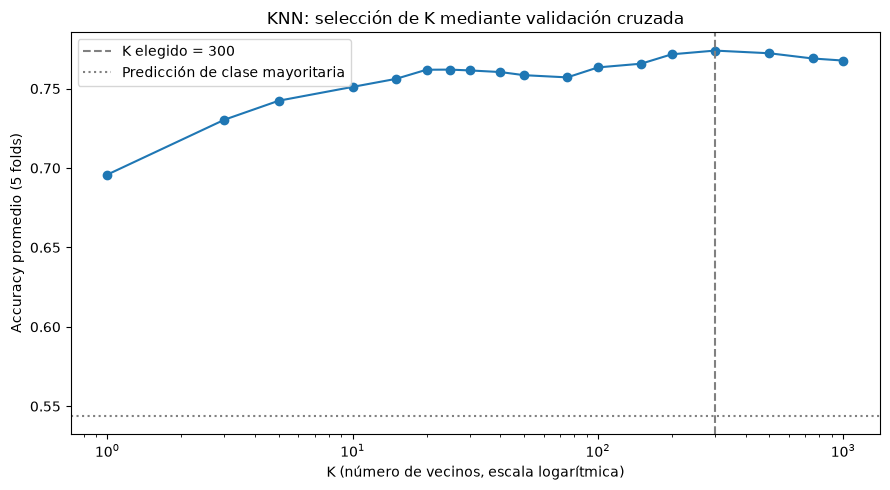

In [8]:
# Gráfico de accuracy
accuracy_mayoria = max(y_train.mean(), 1 - y_train.mean())

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(accuracy_k.index, accuracy_k["accuracy_promedio"], marker="o")
ax.axvline(k_cv, linestyle="--", color="gray", label=f"K elegido = {k_cv}")
ax.axhline(accuracy_mayoria, linestyle=":", color="gray",
           label="Predicción de clase mayoritaria")
ax.set_xscale("log")
ax.set_xlabel("K (número de vecinos, escala logarítmica)")
ax.set_ylabel("Accuracy promedio (5 folds)")
ax.set_title("KNN: selección de K mediante validación cruzada")
ax.legend()
fig.tight_layout()
fig.savefig(carpeta_figuras / "knn_accuracy_cv.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
# Modelo KNN final seleccionado por CV: se estima con todo el entrenamiento.
knn_cv = KNeighborsClassifier(n_neighbors=k_cv).fit(Z_train, y_train)
print(f"KNN con K-CV estimado con {len(X_train)} observaciones de entrenamiento.")

# Aviso metodológico si la grilla termina mientras el accuracy sigue mejorando.
if k_cv == max(grilla_k):
    print("ATENCIÓN: el K elegido está en el extremo derecho de la grilla; "
          "conviene ampliar los K evaluados.")
else:
    print("El K elegido no está en el extremo derecho de la grilla.")

KNN con K-CV estimado con 13692 observaciones de entrenamiento.
El K elegido no está en el extremo derecho de la grilla.


### Archivos generados

- `B_Outputs/B_Table/tabla_knn_k_fijos.csv`: resultados descriptivos del inciso 8.
- `B_Outputs/B_Table/tabla_knn_cv_folds.csv`: accuracy de cada K y fold.
- `B_Outputs/B_Table/tabla_knn_cv.csv`: accuracy promedio y desvío entre folds para cada K.
- `B_Outputs/B_Figure/knn_accuracy_cv.png`: gráfico del inciso 9.

Generación de tablas Latex a partir de los CSV para incluir en el informe

In [10]:
from pathlib import Path
import pandas as pd

# Se ejecuta despues de guardar los CSV de los incisos 8 y 9.

def porcentaje(x):
    return f"{100*x:.2f}".replace(".", ",") + r"\%"

def puntos(x):
    return f"{100*x:.2f}".replace(".", ",")

res_8 = pd.read_csv(carpeta_tablas / "tabla_knn_k_fijos.csv")
tabla_latex_8 = pd.DataFrame({
    "K": res_8["K"].astype(str),
    "Accuracy en train": res_8["accuracy_train"].map(porcentaje)
})
tex_8 = tabla_latex_8.to_latex(
    index=False, escape=False,
    column_format="rc", position="H",
    caption="Exactitud de KNN en entrenamiento", label="tab:knn_fijos"
)
tex_8 = tex_8.replace(r"\begin{tabular}", r"\centering" + "\n" + r"\begin{tabular}", 1)
(carpeta_tablas / "tabla_knn_k_fijos.tex").write_text(tex_8, encoding="utf-8")

res_9 = pd.read_csv(carpeta_tablas / "tabla_knn_cv.csv")
tabla_latex_9 = pd.DataFrame({
    "K": res_9["K"].astype(str),
    "Accuracy promedio": res_9["accuracy_promedio"].map(porcentaje),
    "Desvío entre folds (pp)": res_9["desvio_entre_folds"].map(puntos)
})
mejor = res_9["accuracy_promedio"].idxmax()
for columna in tabla_latex_9.columns:
    tabla_latex_9.loc[mejor, columna] = (
        r"\textbf{" + tabla_latex_9.loc[mejor, columna] + "}"
    )
tex_9 = tabla_latex_9.to_latex(
    index=False, escape=False,
    column_format="rrr", position="H",
    caption="Exactitud de KNN mediante validación cruzada de cinco folds",
    label="tab:knn_cv"
)
tex_9 = tex_9.replace(r"\begin{tabular}", r"\centering" + "\n" + r"\footnotesize" + "\n" + r"\begin{tabular}", 1)
(carpeta_tablas / "tabla_knn_cv.tex").write_text(tex_9, encoding="utf-8")
print("Tablas LaTeX actualizadas en B_Outputs/B_Table.")

Tablas LaTeX actualizadas en B_Outputs/B_Table.
